In [2]:
!pip install --upgrade numpy==1.25.2

In [1]:
# Basics
import os
import sys
import time
from matplotlib import pyplot as plt
import arviz as az  # Visualization
import pytensor  # Graph-based tensor library
import hssm
import pandas

# import ssms.basic_simulators # Model simulators
import hddm_wfpt
import bambi as bmb

hssm.set_floatX("float32")

# Setting float precision in pytensor
pytensor.config.floatX = "float32"

from jax.config import config

AttributeError: module 'numpy.__config__' has no attribute 'get_info'

In [5]:
dataset = pandas.read_csv("../data/HDDM_data.csv")
dataset["participant_id"] = dataset["subj_idx"]
dataset['response'] = dataset['response'].replace(0, -1)
dataset.head(10)

,subj_idx,rt,experimental_treatment_selected,trial_index,condition,risk,gain,no_effect,Optimize,Q1,Q3,IQR,response,domain,subj_idx.1,participant_id
0,AyjDXCOl,1.948725,True,10,Attention (Concentration),35,45,20,0.0,618.4525,1380.565,762.1125,1,1,110,AyjDXCOl
1,AyjDXCOl,1.994525,True,13,Attention (Concentration),15,20,65,0.0,618.4525,1380.565,762.1125,1,1,110,AyjDXCOl
2,AyjDXCOl,0.558885,True,16,Attention (Concentration),25,70,5,0.0,618.4525,1380.565,762.1125,1,1,110,AyjDXCOl
3,AyjDXCOl,1.670090,False,19,Attention (Concentration),25,45,30,0.0,618.4525,1380.565,762.1125,-1,1,110,AyjDXCOl
4,AyjDXCOl,1.499020,False,22,Attention (Concentration),45,30,25,0.0,618.4525,1380.565,762.1125,-1,1,110,AyjDXCOl
5,AyjDXCOl,0.955915,True,25,Attention (Concentration),5,70,25,0.0,618.4525,1380.565,762.1125,1,1,110,AyjDXCOl
6,AyjDXCOl,1.564935,False,28,Attention (Concentration),45,45,10,0.0,618.4525,1380.565,762.1125,-1,1,110,AyjDXCOl
7,AyjDXCOl,0.793320,False,31,Attention (Concentration),25,55,20,0.0,618.4525,1380.565,762.1125,-1,1,110,AyjDXCOl
8,AyjDXCOl,0.845140,False,34,Attention (Concentration),60,15,25,0.0,618.4525,1380.565,762.1125,-1,1,110,AyjDXCOl
9,AyjDXCOl,1.098485,False,37,Attention (Concentration),25,10,65,0.0,618.4525,1380.565,762.1125,-1,1,110,AyjDXCOl


In [ ]:
# Opting for the hierarchical model instead
# simple_ddm_model = hssm.HSSM(data=dataset)
# print(simple_ddm_model)

In [7]:
hssm.__version__

'0.2.0b1'

In [6]:
hier_model = hssm.HSSM(
    data=dataset, hierarchical=True, prior_settings="safe")
print(hier_model)

Hierarchical Sequential Sampling Model
Model: ddm

Response variable: rt,response
Likelihood: analytical
Observations: 35492

Parameters:

v:
    Formula: v ~ 1 + (1|participant_id)
    Priors:
        v_Intercept ~ Normal(mu: 2.0, sigma: 3.0)
        v_1|participant_id ~ Normal(mu: 0.0, sigma: Weibull(alpha: 1.5, beta: 0.30000001192092896))
    Link: identity
    Explicit bounds: (-inf, inf)
a:
    Formula: a ~ 1 + (1|participant_id)
    Priors:
        a_Intercept ~ Gamma(mu: 1.5, sigma: 0.75)
        a_1|participant_id ~ Normal(mu: 0.0, sigma: Weibull(alpha: 1.5, beta: 0.30000001192092896))
    Link: identity
    Explicit bounds: (0.0, inf)
z:
    Formula: z ~ 1 + (1|participant_id)
    Priors:
        z_Intercept ~ Gamma(mu: 10.0, sigma: 10.0)
        z_1|participant_id ~ Normal(mu: 0.0, sigma: Weibull(alpha: 1.5, beta: 0.30000001192092896))
    Link: identity
    Explicit bounds: (0.0, 1.0)
t:
    Formula: t ~ 1 + (1|participant_id)
    Priors:
        t_Intercept ~ Gamma(mu: 0.40

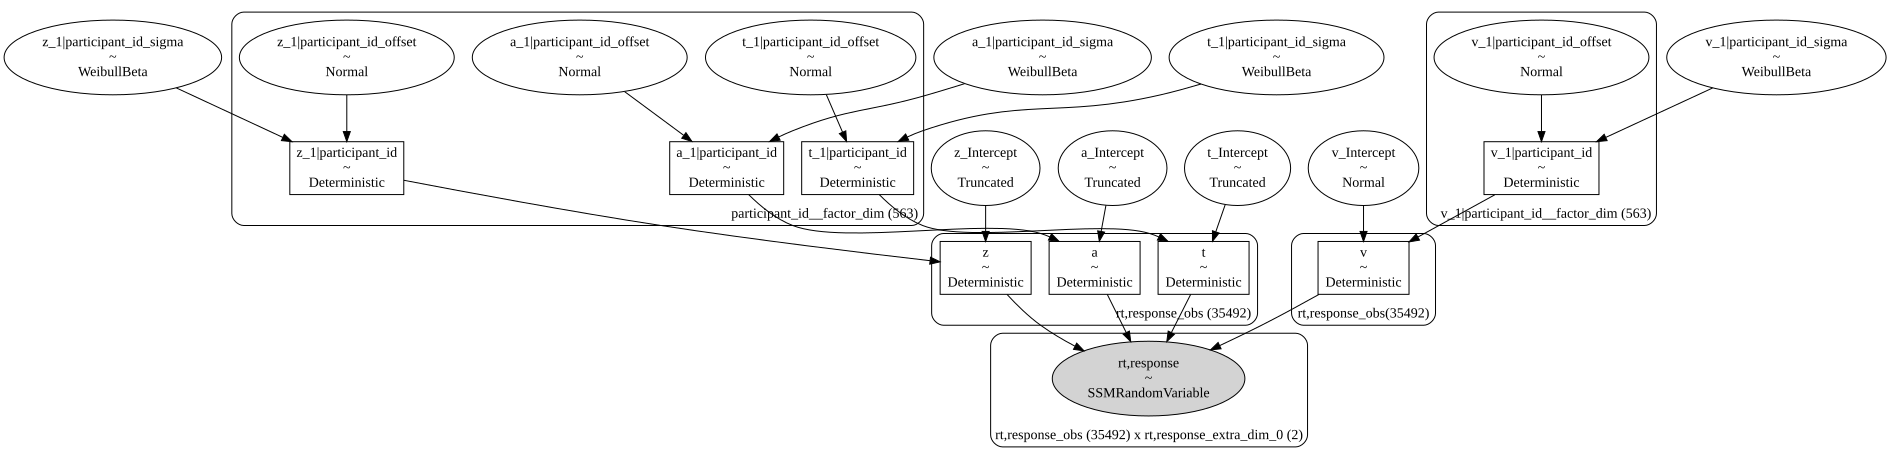

In [5]:
hier_model.graph()

In [8]:
# This was the final model that was run for the 4 parameter DDM

infer_data_hier_model = hier_model.sample(
    sampler="nuts_numpyro",  # type of sampler to choose, 'nuts_numpyro', 'nuts_blackjax' of default pymc nuts sampler
    cores=4,  # how many cores to use
    chains=3,  # how many chains to run
    draws=10000,  # number of draws from the markov chain
    tune=5000,  # number of burn-in samples
    idata_kwargs=dict(log_likelihood=False),  # return log likelihood
)  # mp_ctx="forkserver")

# infer_data_hier_model = hier_model.sample(
#     sampler="nuts_numpyro",  # type of sampler to choose, 'nuts_numpyro', 'nuts_blackjax' of default pymc nuts sampler
#     cores=4,  # how many cores to use
#     chains=3,  # how many chains to run
#     draws=10000,  # number of draws from the markov chain
#     tune=1000,  # number of burn-in samples
#     idata_kwargs=dict(log_likelihood=True),  # return log likelihood
# )  # mp_ctx="forkserver")

Compiling...
Compilation time = 0:00:04.498527
Sampling...
C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\jax\_src\numpy\array_methods.py:64: UserWarning: Explicitly requested dtype float64 requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.
  return lax_numpy.astype(arr, dtype)
C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\jax\_src\numpy\array_methods.py:64: UserWarning: Explicitly requested dtype float64 requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.
  return lax_numpy.astype(arr, dtype)
Compiling.. :   0%|                                                      

In [3]:
az.plot_trace(
    infer_data_hier_model,
    var_names="~log_likelihood",  # we exclude the log_likelihood traces here
)
plt.tight_layout()

C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\arviz\utils.py:134: UserWarning: Items starting with ~: ['log_likelihood'] have not been found and will be ignored
  warnings.warn(
C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\arviz\stats\density_utils.py:487: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")
C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\arviz\stats\density_utils.py:487: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")
C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\arviz\stats\density_utils.py:487: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")
C:\Users\Brian Kim\anaconda3\envs\HSSM\Lib\site-packages\arviz\stats\density

MemoryError: Unable to allocate 7.93 GiB for an array with shape (30000, 35492) and data type int64

Error in callback <function _draw_all_if_interactive at 0x00000279A60C7060> (for post_execute):



KeyboardInterrupt



Error in callback <function flush_figures at 0x0000027980062660> (for post_execute):


KeyboardInterrupt: 

In [6]:
import pickle
# Replace 'your_file_path.pkl' with your desired file path and name
with open('infer_data_hier_model.pkl', 'wb') as file:
    pickle.dump(infer_data_hier_model, file)

In [2]:
import pickle

# Load the object from the file
with open('infer_data_hier_model.pkl', 'rb') as file:
    infer_data_hier_model = pickle.load(file)

In [9]:
suuum = az.summary(infer_data_hier_model)

In [11]:
suuum

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
v_Intercept,2.517,0.438,1.899,2.854,0.253,0.200,3.0,3.0,9.544380e+15
v_1|participant_id_sigma,0.266,0.153,0.151,0.482,0.088,0.070,3.0,3.0,9.544380e+15
a_Intercept,1.489,0.258,1.141,1.757,0.149,0.118,3.0,3.0,9.544380e+15
a_1|participant_id_sigma,0.267,0.111,0.115,0.380,0.064,0.051,3.0,3.0,9.544380e+15
z_Intercept,0.467,0.064,0.391,0.547,0.037,0.029,3.0,3.0,9.544380e+15
...,...,...,...,...,...,...,...,...,...
t[35487],0.229,0.327,-0.230,0.516,0.189,0.149,3.0,3.0,9.544380e+15
t[35488],0.229,0.327,-0.230,0.516,0.189,0.149,3.0,3.0,9.544380e+15
t[35489],0.229,0.327,-0.230,0.516,0.189,0.149,3.0,3.0,9.544380e+15
t[35490],0.229,0.327,-0.230,0.516,0.189,0.149,3.0,3.0,9.544380e+15


In [ ]:
infer_data_hier_model.log_likelihood